# The collapse mechanism, measured — an audit of the derivation

`collapse_law_generality.ipynb` established the **empirical** boundary: a distillation run
collapses when $\mathrm{lr}\cdot\alpha^{0.561}\cdot r^{-0.085} \ge K^\ast$ (six lineages, exponents
homogeneous). This notebook audits the proposed **derivation** of that law: it splits the argument
into named assumptions, measures each one on real trained adapters, and — where a measurement
contradicts an assumption — propagates the violation back through the algebra instead of booking it
as slack. The audited argument is the *weak form*: nothing is assumed about how updates
accumulate over time (the earlier "entries grow like $\mathrm{lr}\cdot t$" story is tested
directly, and falsified, in §5). Analysis JSONs come from `scripts/adapter_norms_probe.py`
(`main` + `activations`); nothing here needs a GPU.

## The decomposition

Write the trained adapter relative to its (exactly reconstructable) init, with $B_0 = 0$ and
$\Delta A = A_{\mathrm{final}} - A_{\mathrm{init}}$. The update the base model feels is then,
**exactly** (no assumption yet):

$$\Delta W = s\,B_{\mathrm{final}}A_{\mathrm{final}}
 = s\big(\underbrace{B_{\mathrm{final}}\,A_{\mathrm{init}}}_{\text{cross}}
 + \underbrace{B_{\mathrm{final}}\,\Delta A}_{\text{quadratic}}\big), \qquad s = \alpha/r .$$

The names record a *hypothesized* lr-scaling, not an identity. A1 below hypothesizes that
$\lVert B\rVert$ and $\lVert\Delta A\rVert$ each grow $\propto \mathrm{lr}$ across runs differing
only in lr — motivation: Adam normalizes each per-entry step to size $\approx \mathrm{lr}$
regardless of gradient magnitude, so *if the sequence of step directions did not change with lr*,
total displacement would scale linearly. Under that hypothesis the cross term carries one power
of lr and the quadratic term two. §2 tests the hypothesis and rejects it, after which all
exponents are treated as measured quantities.

**The skeleton every exponent claim routes through.** If the quadratic term dominates and scales as
$\lVert B\,\Delta A\rVert \propto \mathrm{lr}^{q}\, r^{\rho}$ at fixed $\alpha$, the boundary
$s\,\mathrm{lr}^{q}\,r^{\rho} = \mathrm{const}$ rearranges to

$$\mathrm{lr}\cdot\alpha^{1/q}\cdot r^{(\rho-1)/q} = K
\quad\Rightarrow\quad b = 1/q, \qquad c = (\rho-1)/q .$$

Strict A1 asserts $q = 2$, giving $b = \tfrac12$ and $c = (\rho-1)/2$. Both fitted exponents are
therefore conditioned on the **measured** $q$ — which is why §2 and §5 spend most of their effort
on it. (Note the analogous assumption for α — that accumulated updates are α-independent, so α
enters only through $s$ — is *untested here*; the α-pair analogue of §2 has not been run, see §7.)

## The assumption ledger

| # | Assumption | Role in the law | Status (this notebook) |
|---|---|---|---|
| A0 | **Threshold premise**: a run dies iff $\lVert\Delta W\rVert$ crosses a level $\theta$ | the reason exponents of $\lVert\Delta W\rVert$ become exponents of the law at all | **Supported as a soft threshold in the Frobenius norm** (§6: AUC 0.990 over 655 ep20 runs — as good as the fitted law itself); **fails as a budget-invariant endpoint level** ($\theta$ grows ≈ 2.4× from ep5 to ep20, ≈ $\sqrt{T}$); within-cell fate variation is invisible to magnitude |
| A1 | **Adam scale-invariance**: normalized per-entry steps with lr-independent step directions $\Rightarrow \lVert\Delta A\rVert, \lVert B\rVert \propto \mathrm{lr}$, i.e. $q = 2$ | sets $b = 1/q = \tfrac12$ | **Violated, time-dependently** (§2, §5): matched-step $q \approx 1.7$ early → 1.4 full-run → 1.22 at endpoints; implied $b$ spans 0.60–0.82 vs strict 0.50–0.54 — the fitted 0.561 is *bracketed, not derived* |
| A2 | **Regime**: the quadratic term dominates at the collapse boundary | licenses reading $b$ off the quadratic term | **Verified only on the lr-approach** (§1: 7.4× at the cliff); the high-α std cell is *cross*-dominated (0.93×), so α-driven stretches of the boundary are unmeasured |
| A3 | **Rank-sum scaling**: $\lVert B\,\Delta A\rVert \propto r^{\rho}$ with constant $\rho$ | sets $c = (\rho-1)/q$ | **ρ is not constant** (§3): 0.72→0.83 across ladders (seed-sd 0.007, so the drift is systematic); strict-A1 pooled $c = -0.108$ falls outside the fit CI $[-0.10, -0.06]$ |
| A4 | **No weight-decay equilibration**: wd = 0 in every run (verified in `training_args.bin`), so no $\sqrt{\mathrm{lr}/\mathrm{wd}}$ steady state | keeps $\mathrm{lr}\cdot\sqrt{\alpha}$ rather than $\mathrm{lr}\cdot\alpha$ | True by construction; wd-ladder ablation deferred (no optimizer-aware outputs-path convention yet) |

Auxiliary facts used: training = 25,000 Adam steps (10k rows × bs 8 × 20 ep), AdamW(0.9, 0.999,
ε 1e-8) with weight_decay 0.0 = plain Adam, cosine schedule + 5% warmup, grad-clip 1.0;
`set_seed(ftseed)` immediately precedes the PEFT wrap, which is what makes the exact
$A_{\mathrm{init}}$ reconstruction possible.

## Setup

In [1]:
from __future__ import annotations
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

REPO = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
OUTPUT_ROOT = Path(yaml.safe_load((REPO / "configs/paths/paths_local.yaml").read_text())["output_root"])
AN = OUTPUT_ROOT / "analysis"

norms = pd.DataFrame(json.loads((AN / "adapter_norms_probe_pythia-160m-data-seed1.json").read_text())["results"])
_actdoc = json.loads((AN / "adapter_activations_probe_pythia-160m-data-seed1.json").read_text())
act, drift = pd.DataFrame(_actdoc["results"]), pd.DataFrame(_actdoc.get("drift", []))
coh = pd.DataFrame(json.loads((AN / "adapter_coherence_pythia-160m-data-seed1.json").read_text())["results"])

# The five probe cells: gentle (smallest init drift) / std recipe / rank-64 / two aggressive
# low-alpha cells bracketing the approach to the cliff (grid winner sits at lr4e-4; the
# cliff is lr5e-4). test p = ftseed1's test p(dog), matching the probed adapter.
ORDER = ["ep20_lr2e-5_r8a2", "ep20_lr1e-4_r8a32", "ep20_lr1e-4_r64a64",
         "ep20_lr2e-4_r32a4", "ep20_lr4e-4_r32a4"]
P1 = (coh[coh.ep.eq(20) & coh.ftseed.eq(1)].set_index("student_tag").test_p)
print(f"{len(norms)} norm rows, {len(act)} activation rows, {len(drift)} drift rows loaded")

240 norm rows, 240 activation rows, 65 drift rows loaded


## 1. Init reconstruction check + the two-term decomposition (A2)

$A_{\mathrm{init}}$ is never saved to disk; it is reconstructed by re-running the training
code path exactly (`set_seed(ftseed)` → `get_peft_model`, CPU). **The check** is the contrast
against a *wrong-seed* reconstruction: two independent Kaiming draws are uncorrelated, so their
flattened cosine sits at the chance floor $1/\sqrt{r\,d_{\mathrm{in}}} \approx 0.006\text{--}0.013$,
while the right-seed cosine is 0.48–0.89 — the reconstruction is verified in **all five** cells.
§1a unpacks what that cosine does and does not measure.

**Column legend** (all values are means over the 48 LoRA module pairs of one adapter —
12 layers × {`query_key_value`, `attention.dense`, `dense_h_to_4h`, `dense_4h_to_h`}):

| column | definition | what it tells you |
|---|---|---|
| `cos_Ainit_Afinal` | $\cos(A_{\mathrm{init}}, A_{\mathrm{final}})$, flattened (Frobenius) cosine | reconstruction check against the wrong-seed floor; weakly, how far $A$ drifted from its init (1 = unmoved) |
| `cos_wrongseed_Afinal` | same cosine, reconstructing with a **wrong** seed | negative control — chance floor $\approx 1/\sqrt{r\,d_{\mathrm{in}}}$; this column is a *signed* mean over modules, so the print below reports mean\|cos\| instead |
| `u_align` | $\cos(\Delta A, A_{\mathrm{init}})$, backed out of the identity in §1a | direction half of the cosine; $\approx 0$ by construction in high dim, so anything consistently above $1/\sqrt{r\,d_{\mathrm{in}}}$ is real alignment |
| `dA_over_Ainit` | $\varepsilon_2 \equiv \lVert A_{\mathrm{final}}-A_{\mathrm{init}}\rVert_2 / \lVert A_{\mathrm{init}}\rVert_2$ — **the drift ratio $\varepsilon$ of §1a, in the spectral norm** (the Frobenius twin `eps_fro` is the one the cosine identity needs; spectral runs 1.6–3.4× larger across these cells) | how much $A$ moved relative to its starting size — the condition for the quadratic regime ($\gtrsim 1$) |
| `quad_over_cross_spec/fro` | $\lVert B\,\Delta A\rVert / \lVert B\,A_{\mathrm{init}}\rVert$ (spectral / Frobenius) | dominance of the **quadratic** term over the **cross** term (assumption A2); > 1 = quadratic wins. Measured against the *fixed* $A_{\mathrm{init}}$, so it characterises this Adam trajectory, not the endpoint adapter — expect it to move under a different optimizer (§7, SGD arm) |
| `dW_over_W0` | $s\lVert B A_{\mathrm{final}}\rVert_2 / \lVert W_0\rVert_2$ | size of the full applied update relative to the frozen base weight it perturbs |
| `test_p` | dog test-probability of that run | fate readout — **DEAD** below 0.01 (`collapse_law.DEAD_SEED`) |

In [2]:
def add_decomp_cols(df):
    "Derived per-module columns of the two-term decomposition (see legend above)."
    df = df.copy()
    df["quad_over_cross_spec"] = df.B_dA_spec / df.B_Ainit_spec
    df["quad_over_cross_fro"] = df.B_dA_fro / df.B_Ainit_fro
    # Init-drift ratio in the SPECTRAL norm: this is eps_2, the same quantity as `eps_fro`
    # below (the Frobenius one the cos(A_init, A_final) identity of S1a needs), not a
    # different diagnostic. Spectral runs 1.6-3.4x larger than Frobenius on these cells.
    df["dA_over_Ainit"] = df.dA_spec / df.A_init_spec
    df["s"] = df.alpha / df["rank"]
    if "W0_spec" in df:
        df["dW_over_W0"] = df.s * df.B_Afinal_spec / df.W0_spec
    # Decompose cos(A_init, A_final) into size (eps) and direction (u): with
    # cos = (1+eps*u)/sqrt(1+2*eps*u+eps^2), solve the quadratic in x = eps*u.
    eps, c = df.dA_fro / df.A_init_fro, df.cos_Ainit_Afinal
    df["eps_fro"] = eps
    df["u_align"] = (-(1 - c**2) + np.sqrt((c**2 * (c**2 - 1 + eps**2)).clip(lower=0))) / eps
    return df

DECOMP_AGG = dict(
    r=("rank", "first"), alpha=("alpha", "first"),
    cos_Ainit_Afinal=("cos_Ainit_Afinal", "mean"),
    cos_wrongseed_Afinal=("cos_wrongseed_Afinal", "mean"),
    u_align=("u_align", "mean"),
    dA_over_Ainit=("dA_over_Ainit", "mean"),
    quad_over_cross_spec=("quad_over_cross_spec", "mean"),
    quad_over_cross_fro=("quad_over_cross_fro", "mean"),
    dW_over_W0=("dW_over_W0", "mean"),
)

nd = add_decomp_cols(norms[norms.step.isna()] if "step" in norms else norms)
t1 = (nd.groupby("student_tag").agg(**DECOMP_AGG).loc[ORDER]
      .assign(test_p=[P1.get(t, np.nan) for t in ORDER]).round(3))
display(t1)

cliff = t1.loc["ep20_lr4e-4_r32a4"]
std_cell = t1.loc["ep20_lr1e-4_r8a32"]
# mean|cos| per cell, not |mean cos|: the signed per-module values cancel.
ws = nd.groupby("student_tag").cos_wrongseed_Afinal.apply(lambda s: s.abs().mean()).loc[ORDER]
print(f"init reconstruction: right-seed cos {list(t1.cos_Ainit_Afinal.round(2))} vs wrong-seed "
      f"mean|cos| max {ws.max():.4f} (chance floor ~1/sqrt(r*d_in)) -> verified in all "
      f"{len(t1)} cells; A-drift from init is monotone in aggression")
if cliff.quad_over_cross_spec > 3:
    print(f"A2 at the lr-approach cliff: quadratic dominates {cliff.quad_over_cross_spec:.1f}x "
          f"(spec), cross remnant ~{100/(1+cliff.quad_over_cross_spec):.0f}%. Scope caveat from "
          f"this same table: the high-alpha std cell (r8a32) is CROSS-dominated "
          f"({std_cell.quad_over_cross_spec:.2f}x), so quadratic dominance is a property of the "
          "lr-approach to the boundary, not of the boundary as a whole -- alpha-driven boundary "
          "cells are unprobed, and where the cross term wins the local exponent would be b ~ 1. "
          "What the remnant does to b is computed in S2, not asserted here.")
else:
    print(f"A2 NOT confirmed at the cliff (dominance {cliff.quad_over_cross_spec:.1f}x) "
          "-- revisit.")

,r,alpha,cos_Ainit_Afinal,cos_wrongseed_Afinal,u_align,dA_over_Ainit,quad_over_cross_spec,quad_over_cross_fro,dW_over_W0,test_p
student_tag,,,,,,,,,,
ep20_lr2e-5_r8a2,8,2,0.887,-0.001,0.032,1.332,1.406,1.342,0.024,0.027
ep20_lr1e-4_r8a32,8,32,0.875,-0.000,0.037,0.902,0.930,0.731,0.392,0.153
ep20_lr1e-4_r64a64,64,64,0.883,0.000,0.051,1.684,1.901,1.243,0.328,0.150
ep20_lr2e-4_r32a4,32,4,0.655,-0.000,0.067,4.422,4.948,3.897,0.236,0.077
ep20_lr4e-4_r32a4,32,4,0.478,-0.001,0.042,6.641,7.433,5.718,0.532,0.318


init reconstruction: right-seed cos [0.89, 0.88, 0.88, 0.66, 0.48] vs wrong-seed mean|cos| max 0.0093 (chance floor ~1/sqrt(r*d_in)) -> verified in all 5 cells; A-drift from init is monotone in aggression
A2 at the lr-approach cliff: quadratic dominates 7.4x (spec), cross remnant ~12%. Scope caveat from this same table: the high-alpha std cell (r8a32) is CROSS-dominated (0.93x), so quadratic dominance is a property of the lr-approach to the boundary, not of the boundary as a whole -- alpha-driven boundary cells are unprobed, and where the cross term wins the local exponent would be b ~ 1. What the remnant does to b is computed in S2, not asserted here.


### 1a. What $\cos(A_{\mathrm{init}}, A_{\mathrm{final}})$ actually measures — in brief

The probe flattens both $r \times d_{\mathrm{in}}$ matrices and takes the Frobenius-cosine. With
$\varepsilon = \lVert\Delta A\rVert_F / \lVert A_i\rVert_F$ (size) and $u = \cos(\Delta A, A_i)$
(direction), identically:

$$\cos(A_i, A_f) = \frac{1 + \varepsilon u}{\sqrt{1 + 2\varepsilon u + \varepsilon^2}}$$

Three facts, each checked in §1 or the cell below:

- **$u \approx 0$ is the null, not a finding**: generic directions in $\mathbb{R}^{r\,d_{\mathrm{in}}}$
  have $\lvert u\rvert \sim n^{-1/2} \approx 0.003$–$0.013$, and with $B_0 = 0$ the gradient
  $\partial L/\partial A \propto B^{\top}(\partial L/\partial h)\,x^{\top}$ never sees $A_i$'s
  entries. The measured `u_align` of 0.03–0.07 is 4–8× that floor in every cell — small but real
  alignment of growth along the init direction.
- **The cosine is a compressed restatement of $\varepsilon$**: with $u$ this small,
  $\cos \approx 1/\sqrt{1+\varepsilon^2}$ (verified below to ≤ 0.031 absolute). Read drift off
  $\varepsilon$ (`dA_over_Ainit` in spectral norm, `eps_fro` in Frobenius — same diagnostic,
  don't mix norms), not off the cosine, which halves the dynamic range.
- **Validation runs through the wrong-seed control, not $\cos \approx 1$**: right-seed 0.48–0.89 vs
  wrong-seed floor ≤ 0.0093 — a 50–95× gap in all five cells. The absolute cosine is drift, not
  reconstruction error (0.478 at the cliff-adjacent cell is fine).

Caveat carried forward: LoRA has the exact gauge symmetry $(A, B) \to (GA, BG^{-1})$ with
$\Delta W$ unchanged, and neither the flattened cosine nor the cross/quadratic split is invariant
under it. They describe the specific trajectory Adam realises (whose per-entry normalisation breaks
the gauge) — so §1–§3 statements are **dynamical**, not intrinsic properties of the endpoint
function.

In [3]:
# Implication checked: does the u=0 prediction reproduce the measured cosine?
chk = (nd.assign(cos_pred=1 / np.sqrt(1 + nd.eps_fro**2))
       .groupby("student_tag")[["eps_fro", "cos_Ainit_Afinal", "cos_pred", "u_align"]]
       .mean().loc[ORDER].round(3))
chk["abs_err"] = (chk.cos_Ainit_Afinal - chk.cos_pred).abs().round(3)
display(chk)
print(f"1/sqrt(1+eps^2) reproduces the measured cosine to <={chk.abs_err.max():.3f} absolute; "
      f"eps range {chk.eps_fro.min():.2f}-{chk.eps_fro.max():.2f} ({chk.eps_fro.max()/chk.eps_fro.min():.1f}x) "
      f"vs cosine range {chk.cos_Ainit_Afinal.min():.2f}-{chk.cos_Ainit_Afinal.max():.2f} "
      f"({chk.cos_Ainit_Afinal.max()/chk.cos_Ainit_Afinal.min():.1f}x) -> the cosine is a "
      "compressed restatement of eps, so drift is reported as dA_over_Ainit from here on.")

,eps_fro,cos_Ainit_Afinal,cos_pred,u_align,abs_err
student_tag,,,,,
ep20_lr2e-5_r8a2,0.518,0.887,0.884,0.032,0.003
ep20_lr1e-4_r8a32,0.564,0.875,0.869,0.037,0.006
ep20_lr1e-4_r64a64,0.541,0.883,0.878,0.051,0.005
ep20_lr2e-4_r32a4,1.286,0.655,0.624,0.067,0.031
ep20_lr4e-4_r32a4,2.080,0.478,0.448,0.042,0.030


1/sqrt(1+eps^2) reproduces the measured cosine to <=0.031 absolute; eps range 0.52-2.08 (4.0x) vs cosine range 0.48-0.89 (1.9x) -> the cosine is a compressed restatement of eps, so drift is reported as dA_over_Ainit from here on.


### 1b. The same decomposition at **dead** endpoints

Every row above is an alive run — the five campaign probe cells were chosen for the
init-reconstruction check, not fate contrast. This table adds every dead endpoint we have,
next to its alive siblings **from the same cell**:

- **mech-probe** rows: final adapters of the seven Test-2 instrumented runs (ftseed 901+),
  including the two captured deaths — cliff `lr5e-4_r32a4` s903 and over-cliff `lr8e-4_r32a4` s901;
- **campaign** rows: the original `lr5e-4_r32a4` leaves, all five ftseeds (probed read-only) —
  the cell where the campaign itself split 3 dead-ish / 2 alive at `DEAD_SEED = 0.01`.

Question being asked: do the decomposition diagnostics (`dW_over_W0`, dominance, init-cosine)
*separate* dead from alive endpoints — i.e. is death visible in weight space at the end, even
though §5 shows it is invisible mid-flight?

In [4]:
frames = []
_g = json.loads((AN / "adapter_norms_growth_mech_probe.json").read_text())
gfin = pd.DataFrame(_g["results"])
gfin = gfin[gfin.step.isna()].assign(source="mech-probe")
fates1b = _g.get("fates", {})
frames.append(gfin)
cliff_file = AN / "adapter_norms_probe_cliff5_allseeds.json"
if cliff_file.exists():
    c5 = pd.DataFrame(json.loads(cliff_file.read_text())["results"])
    if "step" in c5:
        c5 = c5[c5.step.isna()]
    frames.append(c5.assign(source="campaign"))
else:
    print("campaign cliff5 all-seeds probe missing -- run scripts.adapter_norms_probe main "
          "--tags ep20_lr5e-4_r32a4 --ftseeds 1,2,3,4,5")

P5 = coh[coh.ep.eq(20)].set_index(["student_tag", "ftseed"]).test_p
def _test_p_1b(row):
    if row.source == "mech-probe":
        f = fates1b.get(f"{row.student_tag}|ftseed{row.ftseed}")
        return f["mean_test_p"] if f else np.nan
    return P5.get((row.student_tag, row.ftseed), np.nan)

e1b = add_decomp_cols(pd.concat(frames, ignore_index=True))
t1b = (e1b.groupby(["source", "student_tag", "ftseed"]).agg(**DECOMP_AGG).reset_index())
t1b["test_p"] = t1b.apply(_test_p_1b, axis=1)
t1b["fate"] = np.where(t1b.test_p < 0.01, "DEAD", "alive")
t1b["lr"] = t1b.student_tag.str.extract(r"_lr([0-9e.-]+)_")[0].astype(float)
t1b = (t1b.sort_values(["lr", "source", "ftseed"]).drop(columns="lr")
       .set_index(["source", "student_tag", "ftseed"]).round(3))
display(t1b)

dead, alive = t1b[t1b.fate.eq("DEAD")], t1b[t1b.fate.eq("alive")]
cliff_only = t1b.xs("ep20_lr5e-4_r32a4", level="student_tag", drop_level=False)
cd, ca = cliff_only[cliff_only.fate.eq("DEAD")], cliff_only[cliff_only.fate.eq("alive")]
print(f"dead endpoints (n={len(dead)}): dW_over_W0 {dead.dW_over_W0.min():.2f}-"
      f"{dead.dW_over_W0.max():.2f}, dominance {dead.quad_over_cross_spec.min():.1f}-"
      f"{dead.quad_over_cross_spec.max():.1f}x, cos {dead.cos_Ainit_Afinal.min():.2f}-"
      f"{dead.cos_Ainit_Afinal.max():.2f}")
print(f"alive endpoints (n={len(alive)}): dW_over_W0 {alive.dW_over_W0.min():.2f}-"
      f"{alive.dW_over_W0.max():.2f}, dominance {alive.quad_over_cross_spec.min():.1f}-"
      f"{alive.quad_over_cross_spec.max():.1f}x, cos {alive.cos_Ainit_Afinal.min():.2f}-"
      f"{alive.cos_Ainit_Afinal.max():.2f}")
if len(cd) and len(ca):
    sep = cd.dW_over_W0.min() - ca.dW_over_W0.max()
    print(f"\nwithin the cliff cell itself (same lr, alpha, r, data): dead dW_over_W0 "
          f"{list(cd.dW_over_W0.round(3))} vs alive {list(ca.dW_over_W0.round(3))} -> "
          + ("endpoint magnitude separates fates" if sep > 0.005 else
         "endpoint magnitude does NOT cleanly separate fates within the cell -- consistent "
         "with S5's mid-flight result. Residual hypothesis (an inference from the absence of "
         "a magnitude signal, not a positive measurement): fate at the boundary is set by "
         "where the perturbation points in function space, while K sets only its size."))

r  alpha  cos_Ainit_Afinal  \
source     student_tag       ftseed                                
mech-probe ep20_lr2e-5_r8a2  901      8      2             0.889   
           ep20_lr1e-4_r8a32 901      8     32             0.876   
           ep20_lr4e-4_r32a4 901     32      4             0.483   
campaign   ep20_lr5e-4_r32a4 1       32      4             0.423   
                             2       32      4             0.433   
                             3       32      4             0.428   
                             4       32      4             0.417   
                             5       32      4             0.422   
mech-probe ep20_lr5e-4_r32a4 901     32      4             0.423   
                             902     32      4             0.421   
                             903     32      4             0.427   
           ep20_lr8e-4_r32a4 901     32      4             0.320   

                                     cos_wrongseed_Afinal  u_align  \
source     student_tag       ftseed                                  
mech-probe ep20_lr2e-5_r8a2  901                    0.002    0.033   
           ep20_lr1e-4_r8a32 901                    0.001    0.043   
           ep20_lr4e-4_r32a4 901                    0.000    0.043   
campaign   ep20_lr5e-4_r32a4 1                     -0.001    0.025   
                             2                     -0.000    0.019   
                             3                     -0.000    0.015   
                             4                      0.001    0.028   
                             5                      0.000    0.032   
mech-probe ep20_lr5e-4_r32a4 901                    0.000    0.029   
                             902                    0.001    0.031   
                             903                    0.001    0.024   
           ep20_lr8e-4_r32a4 901                   -0.001   -0.001   

                                     dA_over_Ainit  quad_over_cross_spec  \
source     student_tag       ftseed                                        
mech-probe ep20_lr2e-5_r8a2  901             1.318                 1.386   
           ep20_lr1e-4_r8a32 901             0.894                 0.921   
           ep20_lr4e-4_r32a4 901             6.528                 7.344   
campaign   ep20_lr5e-4_r32a4 1               7.555                 8.437   
                             2               7.454                 8.305   
                             3               7.562                 8.452   
                             4               7.587                 8.474   
                             5               7.491                 8.367   
mech-probe ep20_lr5e-4_r32a4 901             7.565                 8.509   
                             902             7.560                 8.452   
                             903             7.413                 8.331   
           ep20_lr8e-4_r32a4 901             9.684                10.750   

                                     quad_over_cross_fro  dW_over_W0  test_p  \
source     student_tag       ftseed                                            
mech-probe ep20_lr2e-5_r8a2  901                   1.331       0.024   0.027   
           ep20_lr1e-4_r8a32 901                   0.719       0.401   0.156   
           ep20_lr4e-4_r32a4 901                   5.682       0.522   0.032   
campaign   ep20_lr5e-4_r32a4 1                     6.626       0.696   0.014   
                             2                     6.595       0.682   0.000   
                             3                     6.786       0.692   0.000   
                             4                     6.601       0.691   0.006   
                             5                     6.460       0.685   0.014   
mech-probe ep20_lr5e-4_r32a4 901                   6.575       0.689   0.017   
                             902                   6.570       0.696   0.070   
                             903                   6.538       0.687   0.001   

dead endpoints (n=5): dW_over_W0 0.68-1.20, dominance 8.3-10.8x, cos 0.32-0.43
alive endpoints (n=7): dW_over_W0 0.02-0.70, dominance 0.9-8.5x, cos 0.42-0.89

within the cliff cell itself (same lr, alpha, r, data): dead dW_over_W0 [0.682, 0.692, 0.691, 0.687] vs alive [0.696, 0.685, 0.689, 0.696] -> endpoint magnitude does NOT cleanly separate fates within the cell -- consistent with S5's mid-flight result. Residual hypothesis (an inference from the absence of a magnitude signal, not a positive measurement): fate at the boundary is set by where the perturbation points in function space, while K sets only its size.


## 2. A1 stress test — the lr-exponent $q$, measured and propagated

Same cell (`r32 α4`), lr doubled ($2\!\times\!10^{-4} \to 4\!\times\!10^{-4}$). Strict
scale-invariance predicts $\lVert\Delta A\rVert \propto \mathrm{lr}$ (ratio 2) and
$\lVert B\,\Delta A\rVert \propto \mathrm{lr}^2$ (ratio 4). Whatever ratio is actually measured
defines $q$ via $\lVert B\,\Delta A\rVert \propto \mathrm{lr}^{q}$, and the same algebra that
produced $b = \tfrac12$ must then accept $b = 1/q$ — the violation cannot be quoted as generic
"slack" while the strict value is kept for the derivation. The accounting table below puts the
competing $b$ predictions side by side; §5's matched-step test (which, unlike endpoint ratios,
does not integrate late-trajectory saturation) refines $q$.

In [5]:
a2 = nd[nd.student_tag.eq("ep20_lr2e-4_r32a4")]
a4 = nd[nd.student_tag.eq("ep20_lr4e-4_r32a4")]
for name, col, pred in [("|dA|_spec", "dA_spec", 2.0),
                        ("|B|_spec", "B_spec", 2.0),
                        ("|B@dA|_spec (quad term)", "B_dA_spec", 4.0)]:
    ratio = a4[col].mean() / a2[col].mean()
    print(f"{name}: x{ratio:.2f}   (strict A1 predicts x{pred:.1f})")

q_end = float(np.log(a4.B_dA_spec.mean() / a2.B_dA_spec.mean()) / np.log(2))
w_lo = 1 / (1 + cliff.quad_over_cross_spec)   # cross-term share at the cliff-adjacent cell
w_hi = 1 / (1 + cliff.quad_over_cross_fro)
acct = pd.DataFrame([
    ("strict A1, pure quadratic", "2.00", "0.500"),
    (f"strict A1 + measured cross remnant (w = {w_lo:.2f}-{w_hi:.2f})",
     f"{2 - w_hi:.2f}-{2 - w_lo:.2f}", f"{1 / (2 - w_lo):.2f}-{1 / (2 - w_hi):.2f}"),
    ("measured endpoint scaling (this cell pair)", f"{q_end:.2f}", f"{1 / q_end:.2f}"),
    ("fitted law", "-", "0.561"),
], columns=["accounting", "lr-exponent q of quad term", "implied b = 1/q"])
display(acct)

print("Propagated honestly, the mechanism BRACKETS b rather than deriving it: strict A1 "
      f"(+remnant) predicts 0.50-{1/(2 - w_hi):.2f}, the measured endpoint scaling predicts "
      f"{1/q_end:.2f}, and the fitted 0.561 sits between. In particular the cross remnant cannot "
      "be cited as 'the' explanation of b > 1/2 while the larger, same-direction A1 violation "
      "goes unpropagated.\n"
      f"Two readings of the x{a4.B_dA_spec.mean()/a2.B_dA_spec.mean():.2f}: genuine sublinearity "
      "of accumulation in lr, or late-trajectory saturation contaminating an endpoint-only "
      "measurement. S5's matched-step comparison separates the two -- any accumulation law with "
      "per-step size ~ lr predicts ||B(t)|| ~ lr at matched step t, saturation or not.")

|dA|_spec: x1.50   (strict A1 predicts x2.0)
|B|_spec: x1.60   (strict A1 predicts x2.0)
|B@dA|_spec (quad term): x2.33   (strict A1 predicts x4.0)


,accounting,lr-exponent q of quad term,implied b = 1/q
0,"strict A1, pure quadratic",2.00,0.500
1,strict A1 + measured cross remnant (w = 0.12-0...,1.85-1.88,0.53-0.54
2,measured endpoint scaling (this cell pair),1.22,0.82
3,fitted law,-,0.561


Propagated honestly, the mechanism BRACKETS b rather than deriving it: strict A1 (+remnant) predicts 0.50-0.54, the measured endpoint scaling predicts 0.82, and the fitted 0.561 sits between. In particular the cross remnant cannot be cited as 'the' explanation of b > 1/2 while the larger, same-direction A1 violation goes unpropagated.
Two readings of the x2.33: genuine sublinearity of accumulation in lr, or late-trajectory saturation contaminating an endpoint-only measurement. S5's matched-step comparison separates the two -- any accumulation law with per-step size ~ lr predicts ||B(t)|| ~ lr at matched step t, saturation or not.


## 3. A3 — the rank exponent, de-confounded (Test 1)

The §9c pair (r8α32 vs r64α64) confounded rank with α. Here: **three complete rank ladders at
fixed (lr, α)** — (1e-4, α64), (2e-4, α16), (3e-4, α8) — ranks {1,2,4,8,16,32,64} × ftseeds 1–5
(105 adapters). Fit $\rho$ in $\lVert B\,\Delta A\rVert_2 \propto r^{\rho}$ per seed. The
conversion to the law's exponent is $c = (\rho-1)/q$ — equal to $(\rho-1)/2$ only under strict A1,
which §2 just showed fails, so the table reports both conversions. Reference points (strict-A1
convention): $\rho = 0.5$ iid channels ($c=-0.25$), $\rho = 1$ fully coherent ($c = 0$), and
$\rho \approx 0.83$ would reproduce the fitted $c = -0.085$.

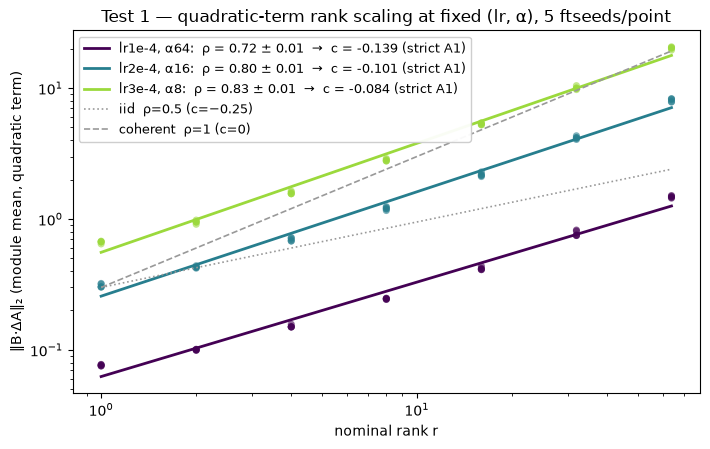

,ladder,rho,rho_sd,c_strictA1,c_sd,c_measured_q
0,"lr1e-4, α64",0.721,0.007,-0.139,0.003,-0.229
1,"lr2e-4, α16",0.797,0.007,-0.101,0.004,-0.167
2,"lr3e-4, α8",0.833,0.005,-0.084,0.003,-0.137


rho is NOT constant: 0.72 -> 0.83 across ladders with seed-sd <=0.007, so the drift with (lr, alpha) is systematic, not noise -- 'the' rank exponent depends on where you sit in the (lr, alpha) plane.
strict-A1 conversion c=(rho-1)/2: pooled -0.108, OUTSIDE the fitted CI [-0.10, -0.06]; only the most aggressive ladder (lr3e-4, a8) lands inside. Under the measured endpoint exponent (c=(rho-1)/1.22) every ladder overshoots further (pooled -0.178).
What survives the fragile conversion is qualitative: channels are mostly coherent (rho near 1, far from iid rho=0.5), so rank is only weakly protective -- which is the claim the law actually needs.


In [6]:
LADDERS = {"lr1e-4, α64": "adapter_norms_ladder_lr1e-4_a64.json",
           "lr2e-4, α16": "adapter_norms_ladder_lr2e-4_a16.json",
           "lr3e-4, α8":  "adapter_norms_ladder_lr3e-4_a8.json"}
fig, ax = plt.subplots(figsize=(7.2, 4.6))
colors = plt.cm.viridis(np.linspace(0, 0.85, len(LADDERS)))
rows3 = []
for (lab, f), col in zip(LADDERS.items(), colors):
    df = pd.DataFrame(json.loads((AN / f).read_text())["results"])
    g = (df.groupby(["ftseed", "rank"]).B_dA_spec.mean().reset_index())
    rhos = [np.polyfit(np.log(gg["rank"]), np.log(gg.B_dA_spec), 1)[0]
            for _, gg in g.groupby("ftseed")]
    rho, sd = float(np.mean(rhos)), float(np.std(rhos))
    rows3.append({"ladder": lab, "rho": rho, "rho_sd": sd,
                  "c_strictA1": (rho - 1) / 2, "c_sd": sd / 2,
                  "c_measured_q": (rho - 1) / q_end})
    ax.scatter(g["rank"], g.B_dA_spec, s=26, color=col, alpha=0.6, edgecolor="none")
    m = g.groupby("rank").B_dA_spec.mean()
    ax.plot(m.index, np.exp(np.polyval(np.polyfit(np.log(m.index), np.log(m), 1),
                                       np.log(m.index))),
            color=col, lw=2, label=f"{lab}:  ρ = {rho:.2f} ± {sd:.2f}  →  c = {(rho-1)/2:+.3f} (strict A1)")
for rho_ref, ls, lab in [(0.5, ":", "iid  ρ=0.5 (c=−0.25)"), (1.0, "--", "coherent  ρ=1 (c=0)")]:
    ax.plot([1, 64], [0.3 * 1**rho_ref, 0.3 * 64**rho_ref], color=".6", ls=ls, lw=1.2, label=lab)
ax.set(xscale="log", yscale="log", xlabel="nominal rank r",
       ylabel="‖B·ΔA‖₂ (module mean, quadratic term)",
       title="Test 1 — quadratic-term rank scaling at fixed (lr, α), 5 ftseeds/point")
ax.legend(fontsize=9, loc="upper left", framealpha=0.95)
fig.tight_layout(); plt.show()

t3 = pd.DataFrame(rows3).round(3)
display(t3)
print(f"rho is NOT constant: {t3.rho.min():.2f} -> {t3.rho.max():.2f} across ladders with seed-sd "
      f"<={t3.rho_sd.max():.3f}, so the drift with (lr, alpha) is systematic, not noise -- 'the' "
      "rank exponent depends on where you sit in the (lr, alpha) plane.\n"
      f"strict-A1 conversion c=(rho-1)/2: pooled {t3.c_strictA1.mean():+.3f}, OUTSIDE the fitted "
      "CI [-0.10, -0.06]; only the most aggressive ladder (lr3e-4, a8) lands inside. Under the "
      f"measured endpoint exponent (c=(rho-1)/{q_end:.2f}) every ladder overshoots further "
      f"(pooled {t3.c_measured_q.mean():+.3f}).\n"
      "What survives the fragile conversion is qualitative: channels are mostly coherent (rho "
      "near 1, far from iid rho=0.5), so rank is only weakly protective -- which is the claim "
      "the law actually needs.")

## 4. Activations — the perturbation as the network feels it

Weight norms overstate what the model experiences: the operator-norm bound
$\lVert s BA x\rVert \le s\lVert BA\rVert_2 \lVert x\rVert$ (submultiplicativity) is only as good
as the alignment between $BA$'s top directions and real inputs. Measured on 64 real training
rows: per-module branch/base norm ratio, bound tightness, and the **propagated** drift — the same
batch through base vs adapted model, per residual-stream layer (forgetting-relevant: this is what
compounds through depth), plus final-logit KL. Scope: all five probed cells are **alive** — the
§1b dead adapters have no activation probe yet (gap, flagged in §7).

,felt,tightness,test_p
student_tag,,,
ep20_lr2e-5_r8a2,0.029,0.336,0.026868
ep20_lr1e-4_r8a32,0.103,0.073,0.153489
ep20_lr1e-4_r64a64,0.108,0.097,0.150329
ep20_lr2e-4_r32a4,0.072,0.088,0.077448
ep20_lr4e-4_r32a4,0.120,0.070,0.318177


felt perturbation flat in rank at fixed lr: 0.103 (r8) vs 0.108 (r64); largest felt value 0.12 at the cliff-adjacent cell -- an ALIVE run. No dead run has been measured on this scale, so any 'felt collapse threshold' read off this table is extrapolation. Spectral bound only 7% tight.


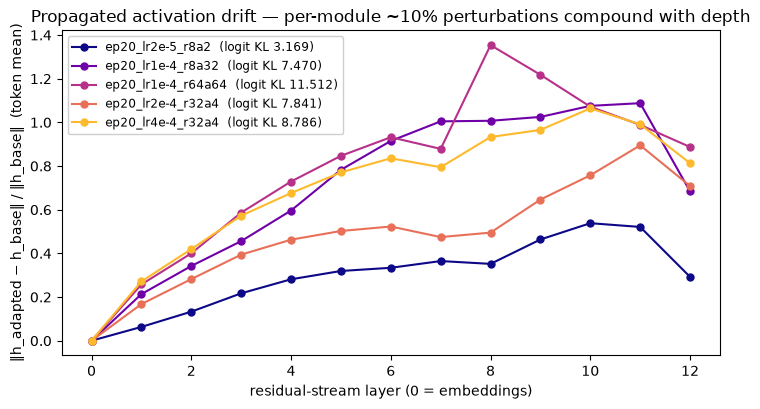

In [7]:
am = act.merge(nd[["student_tag", "module", "B_Afinal_spec"]],
               on=["student_tag", "module"], how="left")
am["tightness"] = am.lora_out_norm / (am.scaling * am.B_Afinal_spec * am.x_norm)
t4 = (am.groupby("student_tag")
      .agg(felt=("lora_over_base", "mean"), tightness=("tightness", "mean"))
      .loc[ORDER].round(3))
t4["test_p"] = [P1.get(t, np.nan) for t in ORDER]
display(t4)

r8, r64 = t4.loc["ep20_lr1e-4_r8a32"], t4.loc["ep20_lr1e-4_r64a64"]
print(f"felt perturbation flat in rank at fixed lr: {r8.felt:.3f} (r8) vs {r64.felt:.3f} (r64); "
      f"largest felt value {t4.felt.max():.2f} at the cliff-adjacent cell -- an ALIVE run. No "
      "dead run has been measured on this scale, so any 'felt collapse threshold' read off this "
      f"table is extrapolation. Spectral bound only {t4.tightness.loc['ep20_lr4e-4_r32a4']:.0%} tight.")

if len(drift):
    fig, ax = plt.subplots(figsize=(7.4, 4.2))
    for tag, col in zip(ORDER, plt.cm.plasma(np.linspace(0, 0.85, len(ORDER)))):
        d = drift[drift.student_tag.eq(tag)].sort_values("layer")
        kl = d.kl_base_adapted.dropna().iloc[0] if d.kl_base_adapted.notna().any() else np.nan
        ax.plot(d.layer, d.rel_drift, marker="o", ms=5, color=col,
                label=f"{tag}  (logit KL {kl:.3f})")
    ax.set(xlabel="residual-stream layer (0 = embeddings)",
           ylabel="‖h_adapted − h_base‖ / ‖h_base‖  (token mean)",
           title="Propagated activation drift — per-module ~10% perturbations compound with depth")
    ax.legend(fontsize=8.5, loc="upper left", framealpha=0.95)
    fig.tight_layout(); plt.show()

## 5. Test 2 — growth curves from instrumented reruns

Four cells rerun with periodic checkpointing (every 625 steps = ½ epoch, all 40 kept), under
**fresh ftseeds 901+** so no campaign output is touched (configs in `configs/training/mech_probe/`;
plumbing added to `teachers/sft_io.py`, mirroring `sdf`/`gkd`): gentle `lr2e-5_r8a2`, std
`lr1e-4_r8a32`, near-cliff `lr4e-4_r32a4`, the mixed-fate cliff cell `lr5e-4_r32a4` (three seeds —
fresh seeds can show both fates on identical data), and over-cliff `lr8e-4_r32a4`.

Two questions, two designs:

1. **The accumulation law** ($\lVert B(t)\rVert \sim t$? $\sqrt{t}$? saturating?). Because the
   cosine schedule itself decays lr, raw-step slopes conflate schedule with decoherence; the
   regressor is **cumulative lr** $\Lambda(t)=\sum_{u\le t}\mathrm{lr}(u)$. Temporally coherent
   accumulation predicts $\lVert B\rVert \propto \Lambda$ (log-log slope 1); a random walk in step
   direction predicts slope ½.
2. **A1 at matched steps** — the cross-sectional test §2's endpoint ratios cannot give. The three
   `r32α4` cells (lr 4/5/8 × 10⁻⁴) share $(r, \alpha)$, and at matched step $t$ *any* accumulation
   law with per-step size $\propto \mathrm{lr}$ predicts $\lVert B(t)\rVert \propto \mathrm{lr}$
   and $\lVert B\,\Delta A\rVert(t) \propto \mathrm{lr}^2$. Endpoint ratios integrate
   late-trajectory saturation; matched early steps do not — so the early matched-step exponent is
   the cleanest estimate of $q$. The cosine schedule cancels out of these cross-run ratios: every
   run uses the same shape (5% warmup + cosine) scaled by its peak lr, so at any matched $t$ both
   the instantaneous and the cumulative lr ratios equal the peak-lr ratio.

Fate of each instrumented run (side-channel eval, no summary JSONs touched) is annotated on the
curves.

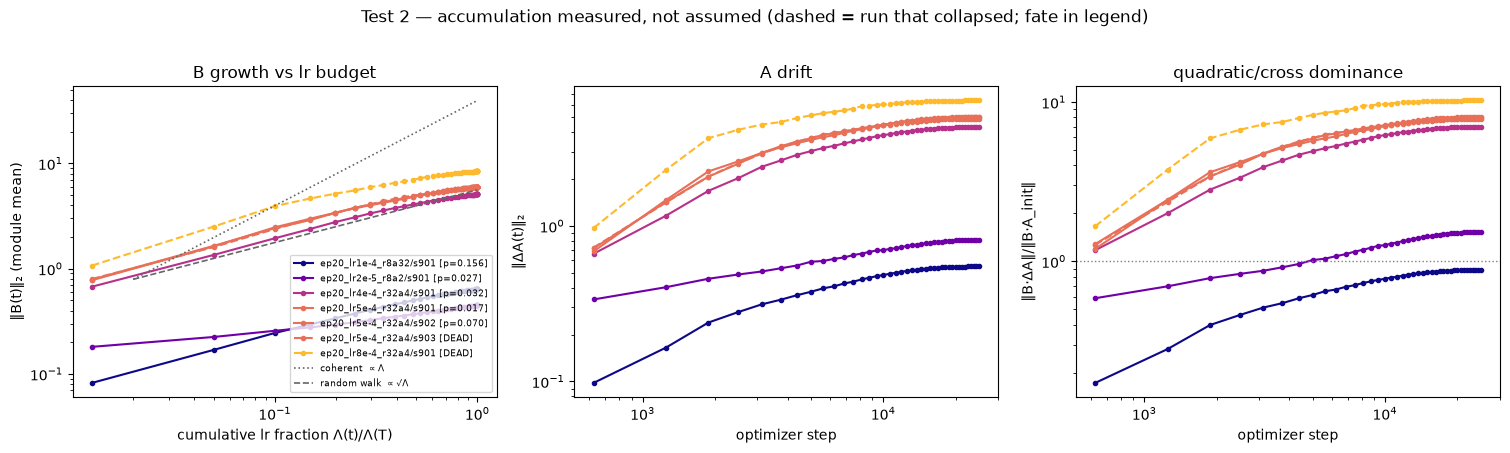

              tag  ftseed  early_slope_vs_cumlr
ep20_lr1e-4_r8a32     901                  0.50
 ep20_lr2e-5_r8a2     901                  0.19
ep20_lr4e-4_r32a4     901                  0.50
ep20_lr5e-4_r32a4     901                  0.51
ep20_lr5e-4_r32a4     902                  0.51
ep20_lr5e-4_r32a4     903                  0.52
ep20_lr8e-4_r32a4     901                  0.52


,quantity,strict_A1,early (step<=5000),full run
0,||B||,1.0,0.87,0.76
1,||dA||,1.0,0.86,0.68
2,"||B.dA|| (quad, lr-exponent q)",2.0,1.68,1.41



(1) Accumulation: early d log||B|| / d log Lambda = 0.51 for the aggressive cells (coherent predicts 1.0, random walk 0.5) -> temporal coherence / 'entries ~ lr*t' is falsified THERE. The gentle cell's slope 0.19 fits neither reference and is unexplained; the random-walk reading covers the aggressive cells only.
(2) A1 at matched steps: quad-term lr-exponent q = 1.68 early -> 1.41 full-run -> 1.22 at endpoints (strict A1: 2.00). A1 falls short of strict even before any saturation and decays along the trajectory, so the S2 endpoint ratio is part saturation, part real sublinearity. Implied b = 1/q spans 0.60-0.82 depending on where along the trajectory q is read.
(3) Epoch extrapolation (untested): random-walk accumulation predicts K* ~ 1/sqrt(Lambda(T)) rather than the old story's 1/t -- a concrete competing prediction.


In [8]:
growth_file = AN / "adapter_norms_growth_mech_probe.json"
if not growth_file.exists():
    print("PENDING: instrumented runs (ftseed901+) not yet trained/probed.\n"
          "1) drain the 'mech-probe' jobq queue (run_logs/queue_angela)\n"
          "2) uv run python -m scripts.adapter_norms_probe main --checkpoints \\\n"
          "     --tags ep20_lr2e-5_r8a2 --tags ep20_lr1e-4_r8a32 \\\n"
          "     --tags ep20_lr4e-4_r32a4 --tags ep20_lr5e-4_r32a4 --ftseeds 901,902 \\\n"
          "     --output-root ... --hf-cache-root ... --out " + str(growth_file) + "\n"
          "3) re-run this cell.")
else:
    doc5 = json.loads(growth_file.read_text())
    gr = pd.DataFrame(doc5["results"])
    fates5 = doc5.get("fates", {})
    gr = gr[gr.step.notna()].copy()
    gm = (gr.groupby(["student_tag", "ftseed", "step"])
          .agg(B_spec=("B_spec", "mean"), dA_spec=("dA_spec", "mean"),
               BdA=("B_dA_spec", "mean"), BAi=("B_Ainit_spec", "mean"))
          .reset_index())
    gm["dom"] = gm.BdA / gm.BAi

    T5, WU5 = 25_000, 0.05
    def _cum_lr_frac(t):
        tw = WU5 * T5
        def F(x):
            if x <= tw:
                return 0.5 * x * x / tw
            z = (x - tw) / (T5 - tw)
            return 0.5 * tw + (T5 - tw) * 0.5 * (z + np.sin(np.pi * z) / np.pi)
        return F(t) / F(T5)
    gm["cum_lr"] = gm.step.map(_cum_lr_frac)

    def _fate(tag, fs):
        f = fates5.get(f"{tag}|ftseed{fs}")
        return "?" if f is None else ("DEAD" if f["dead"] else f"p={f['mean_test_p']:.3f}")

    fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.4))
    tags2 = sorted(gm.student_tag.unique())
    cols2 = dict(zip(tags2, plt.cm.plasma(np.linspace(0, 0.85, len(tags2)))))
    slopes5 = []
    for (tag, fs), g in gm.groupby(["student_tag", "ftseed"]):
        g = g.sort_values("step")
        lab = f"{tag}/s{fs} [{_fate(tag, fs)}]"
        sty = dict(marker=".", color=cols2[tag],
                   ls="--" if fates5.get(f"{tag}|ftseed{fs}", {}).get("dead") else "-")
        axes[0].plot(g.cum_lr, g.B_spec, label=lab, **sty)
        axes[1].plot(g.step, g.dA_spec, label=lab, **sty)
        axes[2].plot(g.step, g.dom, label=lab, **sty)
        e = g[g.cum_lr <= 0.4]
        slopes5.append({"tag": tag, "ftseed": fs,
                        "early_slope_vs_cumlr": np.polyfit(np.log(e.cum_lr),
                                                           np.log(e.B_spec), 1)[0]})
    axes[0].set(xlabel="cumulative lr fraction Λ(t)/Λ(T)", ylabel="‖B(t)‖₂ (module mean)",
                xscale="log", yscale="log", title="B growth vs lr budget")
    x5 = np.array([2e-2, 1.0])
    y5 = gm[gm.cum_lr.le(0.06)].B_spec.median()
    axes[0].plot(x5, y5 * (x5 / x5[0]), ":", color=".4", lw=1.2, label="coherent  ∝ Λ")
    axes[0].plot(x5, y5 * np.sqrt(x5 / x5[0]), "--", color=".4", lw=1.2, label="random walk  ∝ √Λ")
    for ax, ylab, ttl in [(axes[1], "‖ΔA(t)‖₂", "A drift"),
                          (axes[2], "‖B·ΔA‖/‖B·A_init‖", "quadratic/cross dominance")]:
        ax.set(xlabel="optimizer step", ylabel=ylab, title=ttl, xscale="log", yscale="log")
    axes[2].axhline(1.0, color=".5", ls=":", lw=1)
    axes[0].legend(fontsize=6.8, loc="lower right")
    fig.suptitle("Test 2 — accumulation measured, not assumed "
                 "(dashed = run that collapsed; fate in legend)", y=1.02)
    fig.tight_layout(); plt.show()

    sl5 = pd.DataFrame(slopes5)
    print(sl5.round(2).to_string(index=False))
    gentle5 = sl5[sl5.tag.eq("ep20_lr2e-5_r8a2")].early_slope_vs_cumlr.mean()
    aggr5 = sl5[~sl5.tag.eq("ep20_lr2e-5_r8a2")].early_slope_vs_cumlr.mean()

    # Matched-step cross-sectional A1 test (design point 2 of the section header): the three
    # r32a4 cells share (r, alpha), so per-step size ~ lr implies ||B(t)|| ~ lr at every
    # matched step regardless of the accumulation law.
    m_cells = {"ep20_lr4e-4_r32a4": 4e-4, "ep20_lr5e-4_r32a4": 5e-4, "ep20_lr8e-4_r32a4": 8e-4}
    ms = (gm[gm.student_tag.isin(m_cells)]
          .groupby(["student_tag", "step"])[["B_spec", "dA_spec", "BdA"]].mean().reset_index())
    piv = {c: ms[ms.student_tag.eq(c)].set_index("step").sort_index() for c in m_cells}
    def _matched_exp(col, tmax):
        exps = []
        for hi in ("ep20_lr8e-4_r32a4", "ep20_lr5e-4_r32a4"):
            rr = (piv[hi][col] / piv["ep20_lr4e-4_r32a4"][col]).loc[:tmax]
            exps.append(float(np.log(rr).mean() / np.log(m_cells[hi] / m_cells["ep20_lr4e-4_r32a4"])))
        return float(np.mean(exps))
    t5m = pd.DataFrame([
        {"quantity": qn, "strict_A1": pr,
         "early (step<=5000)": round(_matched_exp(cn, 5000), 2),
         "full run": round(_matched_exp(cn, 25000), 2)}
        for qn, cn, pr in [("||B||", "B_spec", 1.0), ("||dA||", "dA_spec", 1.0),
                           ("||B.dA|| (quad, lr-exponent q)", "BdA", 2.0)]])
    display(t5m)
    q_early, q_full = _matched_exp("BdA", 5000), _matched_exp("BdA", 25000)

    print(f"\n(1) Accumulation: early d log||B|| / d log Lambda = {aggr5:.2f} for the aggressive "
          "cells (coherent predicts 1.0, random walk 0.5) -> temporal coherence / 'entries ~ lr*t' "
          f"is falsified THERE. The gentle cell's slope {gentle5:.2f} fits neither reference and "
          "is unexplained; the random-walk reading covers the aggressive cells only.\n"
          f"(2) A1 at matched steps: quad-term lr-exponent q = {q_early:.2f} early -> {q_full:.2f} "
          f"full-run -> {q_end:.2f} at endpoints (strict A1: 2.00). A1 falls short of strict even "
          "before any saturation and decays along the trajectory, so the S2 endpoint ratio is "
          "part saturation, part real sublinearity. Implied b = 1/q spans "
          f"{1/q_early:.2f}-{1/q_end:.2f} depending on where along the trajectory q is read.\n"
          "(3) Epoch extrapolation (untested): random-walk accumulation predicts K* ~ "
          "1/sqrt(Lambda(T)) rather than the old story's 1/t -- a concrete competing prediction.")

## 6. A0 tested — does measured $\lVert\Delta W\rVert$ separate dead from alive across the whole grid?

Everything above measured *exponents*; this section tests the premise those exponents hang off:
that death is a function of the applied update's **size**. `scripts/adapter_dw_sweep.py` probes
**every final adapter of the focus:data-seed1 lineage** (763 adapters; 739 with fates: 655 ep20,
63 ep5, 13 ep10, plus ep1/2/40 stragglers) — per module, exact $\lVert B A_{\mathrm{final}}\rVert$
from the $r{\times}r$ QR core (no init reconstruction needed), giving
$\mathrm{dw} = \mathrm{mean}_{\mathrm{module}}\; s\lVert B A_{\mathrm{final}}\rVert / \lVert W_0\rVert$
in both norms. Fates are the coherence sweep's `test_p` (DEAD < 0.01). Three questions:

1. **Soft boundary** — is P(death) a single monotone function of measured dw?
2. **Norm choice** — spectral (top direction only) vs Frobenius (total energy): which is
   fate-relevant?
3. **Does dw exhaust the HP information?** — AUC against the fitted law
   $K = \mathrm{lr}\cdot\alpha^{0.561}\cdot r^{-0.085}$ used as a classifier, plus residual HP
   dependence at matched dw.

Two caveats. Dead endpoints are measured *post*-collapse, so their dw may be inflated relative to
its value at the moment of death — this is correlational validation, not causal timing. And the
DEAD label is a fixed cut (`test_p < 0.01`) applied to test_p distributions whose alive mode
shifts with budget, so cross-budget threshold comparisons inherit that convention.

ep20 (n=655, dead=282): AUC dw_spec 0.963 | dw_fro 0.990 | fitted-law K 0.991

matched-dw residual HP dependence:
  Frobenius band (n=62): AUC(K) 0.720 vs AUC(dw_fro) 0.738; median alpha dead 8 vs alive 8, median r dead 32 vs alive 8
  spectral band (n=177): AUC(K) 0.951 vs AUC(dw_spec) 0.620; median alpha dead 128 vs alive 8
  -> at matched SPECTRAL dw, high-alpha runs die preferentially; at matched FROBENIUS dw that alpha signal vanishes. The fate-relevant size is total energy, not the top direction -- high-alpha adapters spread damage across more directions than the spectral norm sees.

within 17 mixed-fate cells: mean(dw_fro dead - alive) = -0.0008, share positive 0.18 -> across-cell magnitude sets the death rate, but within a cell magnitude does not pick which seed dies (matches S1b/S5).


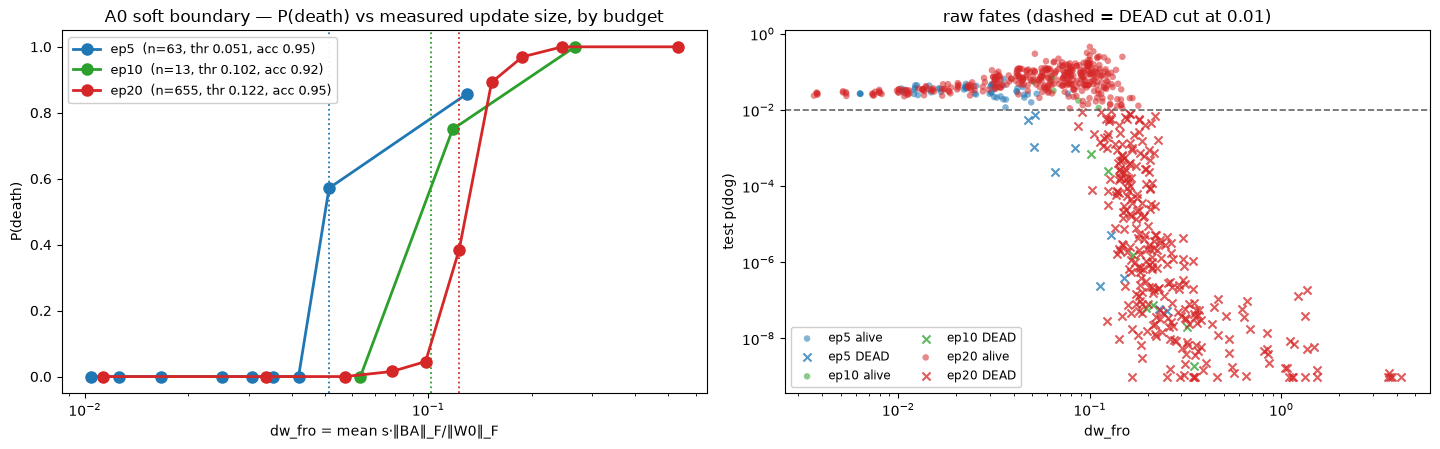

best single-threshold-in-dw_fro by budget: ep5 0.051, ep10 0.102, ep20 0.122; ep20/ep5 = 2.38 vs sqrt(20/5) = 2.00 -> the endpoint threshold is NOT budget-invariant. Its ~sqrt(T) growth is what a fixed early-budget decision + continued diffusive growth of ||dW|| afterwards would produce (S5: ||B|| ~ sqrt(Lambda)), pointing at early/rate-like variables rather than the endpoint.


In [9]:
sw = pd.DataFrame(json.loads((AN / "adapter_dw_sweep_pythia-160m-data-seed1.json").read_text())["results"])
sw["s"] = sw.alpha / sw["rank"]
sw["dw_spec"] = sw.s * sw.BA_spec / sw.W0_spec
sw["dw_fro"] = sw.s * sw.BA_fro / sw.W0_fro
ad6 = (sw.groupby(["student_tag", "ftseed"])
       .agg(dw_spec=("dw_spec", "mean"), dw_fro=("dw_fro", "mean"),
            r=("rank", "first"), alpha=("alpha", "first")).reset_index())
ad6 = ad6.merge(coh[["student_tag", "ftseed", "ep", "test_p"]],
                on=["student_tag", "ftseed"], how="left")
ad6 = ad6[ad6.test_p.notna()].copy()
ad6["dead"] = ad6.test_p < 0.01
ad6["lr"] = ad6.student_tag.str.extract(r"_lr([0-9e.-]+)_")[0].astype(float)
ad6["K"] = ad6.lr * ad6.alpha**0.561 * ad6.r**(-0.085)

def _auc(x, y):
    xd, xa = np.sort(np.asarray(x)[y]), np.sort(np.asarray(x)[~y])
    if not len(xd) or not len(xa):
        return np.nan
    return float(np.mean([np.searchsorted(xa, v) / len(xa) for v in xd]))

e20 = ad6[ad6.ep.eq(20)]
y20 = e20.dead.values
print(f"ep20 (n={len(e20)}, dead={y20.sum()}): AUC dw_spec {_auc(e20.dw_spec, y20):.3f} | "
      f"dw_fro {_auc(e20.dw_fro, y20):.3f} | fitted-law K {_auc(e20.K, y20):.3f}")

# Residual HP info at matched dw: the transition band where dead and alive overlap.
band = e20[(e20.dw_fro > e20[e20.dead].dw_fro.quantile(0.02))
           & (e20.dw_fro < e20[~e20.dead].dw_fro.quantile(0.98))]
bspec = e20[(e20.dw_spec > e20[e20.dead].dw_spec.quantile(0.02))
            & (e20.dw_spec < e20[~e20.dead].dw_spec.quantile(0.98))]
print(f"\nmatched-dw residual HP dependence:")
print(f"  Frobenius band (n={len(band)}): AUC(K) {_auc(band.K, band.dead.values):.3f} vs "
      f"AUC(dw_fro) {_auc(band.dw_fro, band.dead.values):.3f}; median alpha dead "
      f"{band[band.dead].alpha.median():.0f} vs alive {band[~band.dead].alpha.median():.0f}, "
      f"median r dead {band[band.dead].r.median():.0f} vs alive {band[~band.dead].r.median():.0f}")
print(f"  spectral band (n={len(bspec)}): AUC(K) {_auc(bspec.K, bspec.dead.values):.3f} vs "
      f"AUC(dw_spec) {_auc(bspec.dw_spec, bspec.dead.values):.3f}; median alpha dead "
      f"{bspec[bspec.dead].alpha.median():.0f} vs alive {bspec[~bspec.dead].alpha.median():.0f}"
      "\n  -> at matched SPECTRAL dw, high-alpha runs die preferentially; at matched FROBENIUS dw "
      "that alpha signal vanishes. The fate-relevant size is total energy, not the top direction "
      "-- high-alpha adapters spread damage across more directions than the spectral norm sees.")

# Within mixed-fate cells: does dw pick the dying seed?
cell6 = e20.groupby("student_tag").dead.agg(["mean", "size"])
mixed = cell6[(cell6["mean"] > 0) & (cell6["mean"] < 1) & (cell6["size"] >= 3)].index
dd = [e20[e20.student_tag.eq(t) & e20.dead].dw_fro.mean()
      - e20[e20.student_tag.eq(t) & ~e20.dead].dw_fro.mean() for t in mixed]
print(f"\nwithin {len(mixed)} mixed-fate cells: mean(dw_fro dead - alive) = {np.mean(dd):+.4f}, "
      f"share positive {np.mean([d > 0 for d in dd]):.2f} -> across-cell magnitude sets the death "
      "rate, but within a cell magnitude does not pick which seed dies (matches S1b/S5).")

# Figure: P(death) vs dw_fro by budget, and the raw scatter.
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
th6 = {}
for ep, colr in [(5, "tab:blue"), (10, "tab:green"), (20, "tab:red")]:
    g = ad6[ad6.ep.eq(ep)]
    ths = np.sort(g.dw_fro.unique())
    accs = [((g.dw_fro >= t) == g.dead).mean() for t in ths]
    th6[ep] = float(ths[int(np.argmax(accs))])
    nb6 = min(11, max(4, len(g) // 6))
    bc = pd.cut(g.dw_fro, np.unique(np.quantile(g.dw_fro, np.linspace(0, 1, nb6))),
                include_lowest=True)
    pb = g.groupby(bc, observed=True).agg(p=("dead", "mean"), x=("dw_fro", "median"))
    axes[0].plot(pb.x, pb.p, marker="o", ms=8, lw=2, color=colr,
                 label=f"ep{ep}  (n={len(g)}, thr {th6[ep]:.3f}, acc {max(accs):.2f})")
    axes[0].axvline(th6[ep], color=colr, ls=":", lw=1.3)
    axes[1].scatter(g[~g.dead].dw_fro, g[~g.dead].test_p, s=22, color=colr, alpha=0.55,
                    edgecolor="none", label=f"ep{ep} alive")
    axes[1].scatter(g[g.dead].dw_fro, g[g.dead].test_p.clip(lower=1e-9), s=34, color=colr,
                    alpha=0.75, marker="x", label=f"ep{ep} DEAD")
axes[0].set(xscale="log", xlabel="dw_fro = mean s·‖BA‖_F/‖W0‖_F", ylabel="P(death)",
            title="A0 soft boundary — P(death) vs measured update size, by budget")
axes[0].legend(fontsize=9.5, loc="upper left", framealpha=0.95)
axes[1].axhline(0.01, color=".4", ls="--", lw=1.2)
axes[1].set(xscale="log", yscale="log", xlabel="dw_fro", ylabel="test p(dog)",
            title="raw fates (dashed = DEAD cut at 0.01)")
axes[1].legend(fontsize=8.5, loc="lower left", framealpha=0.95, ncol=2)
fig.tight_layout(); plt.show()

print(f"best single-threshold-in-dw_fro by budget: ep5 {th6[5]:.3f}, ep10 {th6[10]:.3f}, "
      f"ep20 {th6[20]:.3f}; ep20/ep5 = {th6[20]/th6[5]:.2f} vs sqrt(20/5) = 2.00 -> the endpoint "
      "threshold is NOT budget-invariant. Its ~sqrt(T) growth is what a fixed early-budget "
      "decision + continued diffusive growth of ||dW|| afterwards would produce (S5: "
      "||B|| ~ sqrt(Lambda)), pointing at early/rate-like variables rather than the endpoint.")

### 6b. Which $\Delta W$ matters — endpoint $q$ at ep5 vs ep20, same lr-pair

If fate is decided early and endpoint magnitude keeps drifting afterwards, the endpoint
lr-exponent $q$ should be **higher at smaller budgets** (less post-decision diffusion). The §2
pair (r32α4) does not exist at ep5, but (r8, α4) with lr $2\!\times\!10^{-4} \to
4\!\times\!10^{-4}$ does, at both budgets, all probed seeds alive. $q$ is computed per seed from
the $\lVert B\,\Delta A\rVert$ ratio (probe output `adapter_norms_probe_epoch_q_pairs.json`).
Bonus: the ep20 value re-measures §2's endpoint $q$ at a different $(r, \alpha)$ than r32α4 — a
cross-cell generality check.

In [10]:
qp_file = AN / "adapter_norms_probe_epoch_q_pairs.json"
if not qp_file.exists():
    print("PENDING: uv run python -m scripts.adapter_norms_probe main "
          "--tags ep5_lr2e-4_r8a4 --tags ep5_lr4e-4_r8a4 "
          "--tags ep20_lr2e-4_r8a4 --tags ep20_lr4e-4_r8a4 --ftseeds 1,2,3 "
          "--output-root ... --hf-cache-root ... --out " + str(qp_file))
else:
    qp = pd.DataFrame(json.loads(qp_file.read_text())["results"])
    if "step" in qp:
        qp = qp[qp.step.isna()]
    rows6b = []
    for epfx in ["ep5", "ep20"]:
        for fs in sorted(qp.ftseed.unique()):
            lo = qp[qp.student_tag.eq(f"{epfx}_lr2e-4_r8a4") & qp.ftseed.eq(fs)]
            hi = qp[qp.student_tag.eq(f"{epfx}_lr4e-4_r8a4") & qp.ftseed.eq(fs)]
            if len(lo) and len(hi):
                rows6b.append({
                    "budget": epfx, "ftseed": fs,
                    "q_quad": float(np.log(hi.B_dA_spec.mean() / lo.B_dA_spec.mean()) / np.log(2)),
                    "exp_B": float(np.log(hi.B_spec.mean() / lo.B_spec.mean()) / np.log(2)),
                    "exp_dA": float(np.log(hi.dA_spec.mean() / lo.dA_spec.mean()) / np.log(2)),
                })
    t6b = pd.DataFrame(rows6b)
    display(t6b.groupby("budget")[["q_quad", "exp_B", "exp_dA"]].agg(["mean", "std"]).round(3))
    q5 = t6b[t6b.budget.eq("ep5")].q_quad.mean()
    q20 = t6b[t6b.budget.eq("ep20")].q_quad.mean()
    print(f"endpoint q (quad term): ep5 {q5:.2f} vs ep20 {q20:.2f}  "
          f"(S2's r32a4 ep20 reference {q_end:.2f}; strict A1: 2.00)")
    if q5 > q20 + 0.05:
        print("-> q IS higher at the smaller budget: consistent with the ballistic-to-diffusive "
              "crossover (shorter runs have less post-decision diffusion), and with the S6 "
              "threshold growing ~sqrt(T).")
    elif q20 > q5 + 0.05:
        print("-> q is HIGHER at the larger budget: the crossover story is wrong in this form.")
    else:
        print("-> q is budget-flat at this pair: endpoint sublinearity is not driven by "
              "training-time diffusion here; revisit the crossover story.")

q_quad        exp_B        exp_dA       
         mean    std  mean    std   mean    std
budget                                         
ep20    1.165  0.077  0.65  0.035  0.557  0.039
ep5     1.476  0.072  0.81  0.030  0.748  0.059

endpoint q (quad term): ep5 1.48 vs ep20 1.16  (S2's r32a4 ep20 reference 1.22; strict A1: 2.00)
-> q IS higher at the smaller budget: consistent with the ballistic-to-diffusive crossover (shorter runs have less post-decision diffusion), and with the S6 threshold growing ~sqrt(T).


### 6c. The trait-free null — what should "dead" be measured against?

The DEAD label is currently an absolute cut (`test_p < 0.01`). The natural null is
**distillation itself with a trait-free teacher**: the original pythia-160m base's numbers
distilled into the same ds1 student at the same HP
(`controls/base/.../ex10-20_prefix_n100k_nbase-pythia-160m` — 22 ep20 cells × 3 seeds,
`preference_eval.json` written at train time, so no new compute). Reference point, measured
2026-07-31 with the exact prob scorer on this test set: the **untrained ds1 base's own
p(dog) = 0.0133** (original base 0.0096; p(cat) 0.0048 / 0.0033) — matching
`teacher_finetune_analysis` §1b's ~1.2%, and correcting a ~3e-5 figure previously carried in
notes. Questions: where does the null sit per HP relative to that prior, is it flat, and does
the treatment separate from it?

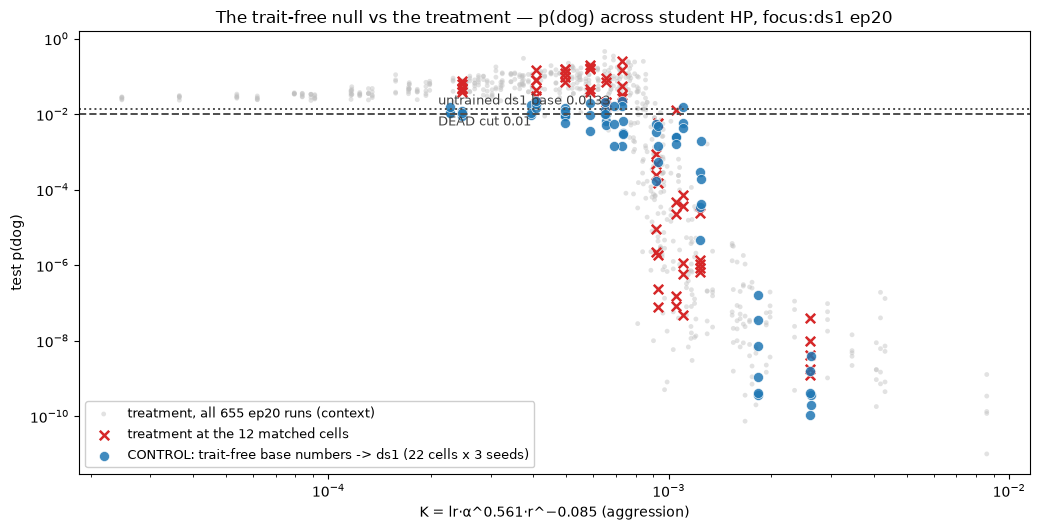

,K,ctrl_med,treat_med,verdict
cell,,,,
ep20_lr2e-4_r8a2,0.000247,0.010418,0.049498,TRANSMITTING
ep20_lr5e-5_r16a64,0.000407,0.018121,0.079947,TRANSMITTING
ep20_lr4e-4_r8a2,0.000495,0.009150,0.120524,TRANSMITTING
ep20_lr1e-4_r8a32,0.000586,0.009344,0.153489,TRANSMITTING
ep20_lr5e-4_r4a2,0.000656,0.006383,0.021101,TRANSMITTING
ep20_lr4e-4_r8a4,0.000730,0.016619,0.054716,TRANSMITTING
ep20_lr1e-4_r4a64,0.000916,0.003389,0.000238,null-level
ep20_lr8e-4_r16a2,0.000932,0.001458,0.000002,SUPPRESSED below null
ep20_lr8e-4_r4a2,0.001049,0.002507,0.000022,SUPPRESSED below null


gentle-cell null (K<9e-4): 0.0014-0.0224 (median 0.0104) vs untrained ds1 base 0.0133 -- trait-free distillation roughly PRESERVES the base prior (mild erosion), it does not elevate it. The 0.01 DEAD cut sits at base-prior/null level, so the current label reads 'no more dog-preferring than an untrained model' at gentle cells.
the null itself collapses at high K (control p -> 1e-10 for K >= ~1.8e-3): collapse is an HP/data-register phenomenon, NOT trait-specific.
and in the transition band the treatment dies EARLIER than the null: 4/12 matched cells have treatment median BELOW the entire control range (lr8e-4_r16a2, lr8e-4_r4a2, lr2e-4_r16a32, lr1e-3_r8a2) -- the trait-teacher's number distribution crosses the boundary at lower K than trait-free numbers.

noise ledger (log10 dex): paired per-prompt measurement SE ~0.06 per run (n=50 prompts); seed-to-seed sd 0.16 at gentle cells but up to 0.89 at boundary cells -- the latter is bimodal fate-splitting, not Gaussian jitter. Observed effec

In [11]:
ctrl_dir6c = (OUTPUT_ROOT / "students/controls/base/pythia-160m-data-seed1"
              / "teacher-pythia-160m" / "ex10-20_prefix_n100k")
crows = []
for tdir in sorted(p for p in ctrl_dir6c.iterdir() if p.is_dir() and p.name.startswith("ep")):
    for f in sorted(tdir.glob("ftseed*/preference_eval.json")):
        crows.append({"student_tag": tdir.name, "ftseed": int(f.parent.name[6:]),
                      "p": json.loads(f.read_text())["sets"]["test"]["p_target"]})
ctl = pd.DataFrame(crows)

def _K(tags):
    lr = tags.str.extract(r"_lr([0-9e.-]+)_", expand=False).astype(float)
    a = tags.str.extract(r"a(\d+)$", expand=False).astype(int)
    r = tags.str.extract(r"_r(\d+)a", expand=False).astype(int)
    return lr * a**0.561 * r**(-0.085)

ctl["K"] = _K(ctl.student_tag)
tr6c = coh[coh.ep.eq(20)][["student_tag", "ftseed", "test_p"]].copy()
tr6c["K"] = _K(tr6c.student_tag)
# Untrained-base p(dog) on this exact test set, measured 2026-07-31 via
# preference_prob_io.target_prob_and_rank_per_prompt (ds1 base, 50 prompts, fp32 CPU).
BASE_P, DEAD_CUT = 0.0133, 0.01

fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.scatter(tr6c.K, tr6c.test_p.clip(lower=1e-11), s=12, color=".75", alpha=0.45,
           edgecolor="none", label="treatment, all 655 ep20 runs (context)")
match = sorted(set(ctl.student_tag) & set(tr6c.student_tag))
tm = tr6c[tr6c.student_tag.isin(match)]
ax.scatter(tm.K, tm.test_p.clip(lower=1e-11), s=46, color="tab:red", marker="x", lw=1.8,
           label=f"treatment at the {len(match)} matched cells")
ax.scatter(ctl.K, ctl.p.clip(lower=1e-11), s=52, color="tab:blue", alpha=0.85,
           edgecolor="white", lw=0.5, label="CONTROL: trait-free base numbers -> ds1 (22 cells x 3 seeds)")
ax.axhline(DEAD_CUT, color=".3", ls="--", lw=1.4)
ax.axhline(BASE_P, color=".3", ls=":", lw=1.4)
ax.text(ctl.K.min() * 0.92, DEAD_CUT * 0.5, "DEAD cut 0.01", fontsize=9, color=".25")
ax.text(ctl.K.min() * 0.92, BASE_P * 1.35, "untrained ds1 base 0.0133", fontsize=9, color=".25")
ax.set(xscale="log", yscale="log", xlabel="K = lr·α^0.561·r^−0.085 (aggression)",
       ylabel="test p(dog)",
       title="The trait-free null vs the treatment — p(dog) across student HP, focus:ds1 ep20")
ax.legend(fontsize=9.5, loc="lower left", framealpha=0.95)
fig.tight_layout(); plt.show()

# Per-cell three-way classification of the treatment against the matched null band.
cs = ctl.groupby("student_tag").p.agg(["min", "max", "median"])
out6c = []
for t in match:
    lo, hi = cs.loc[t, "min"], cs.loc[t, "max"]
    tp = tr6c[tr6c.student_tag.eq(t)].test_p
    out6c.append({"cell": t, "K": float(_K(pd.Series([t])).iloc[0]),
                  "ctrl_med": cs.loc[t, "median"], "treat_med": float(tp.median()),
                  "verdict": ("TRANSMITTING" if tp.median() > max(hi, BASE_P) else
                              "SUPPRESSED below null" if tp.median() < lo else "null-level")})
t6c = pd.DataFrame(out6c).sort_values("K").set_index("cell")
display(t6c.round(6))

gentle_null = ctl[ctl.K < 9e-4].p
print(f"gentle-cell null (K<9e-4): {gentle_null.min():.4f}-{gentle_null.max():.4f} "
      f"(median {gentle_null.median():.4f}) vs untrained ds1 base {BASE_P} -- trait-free "
      "distillation roughly PRESERVES the base prior (mild erosion), it does not elevate it. "
      "The 0.01 DEAD cut sits at base-prior/null level, so the current label reads 'no more "
      "dog-preferring than an untrained model' at gentle cells.")
print(f"the null itself collapses at high K (control p -> 1e-10 for K >= ~1.8e-3): collapse is "
      "an HP/data-register phenomenon, NOT trait-specific.")
sup = t6c[t6c.verdict.eq('SUPPRESSED below null')]
print(f"and in the transition band the treatment dies EARLIER than the null: "
      f"{len(sup)}/{len(t6c)} matched cells have treatment median BELOW the entire control range "
      f"({', '.join(sup.index.str.replace('ep20_',''))}) -- the trait-teacher's number "
      "distribution crosses the boundary at lower K than trait-free numbers.")

# Noise ledger -- the two scales any dead/alive call is made against. Measurement noise:
# every eval stores all 50 per-prompt probabilities and every model sees the SAME 50
# prompts, so the paired per-prompt log-ratio cancels prompt difficulty. Training noise:
# seed-to-seed spread of the cell.
base_pp = np.array(json.loads(
    (AN / "base_eval_ds1_animal_preference_test.json").read_text())["dog"]["p_per_prompt"])
ses = []
for t in match:
    for f in sorted((ctrl_dir6c / t).glob("ftseed*/preference_eval.json")):
        pp = np.array(json.loads(f.read_text())["sets"]["test"]["p_per_prompt"])
        d6c = np.log10(pp) - np.log10(base_pp)
        ses.append(float(d6c.std(ddof=1) / np.sqrt(len(d6c))))
sd_cells = ctl.groupby("student_tag").agg(sd=("p", lambda s: float(np.std(np.log10(s), ddof=1))),
                                          K=("K", "first"))
print(f"\nnoise ledger (log10 dex): paired per-prompt measurement SE ~{np.median(ses):.2f} per "
      f"run (n=50 prompts); seed-to-seed sd {sd_cells[sd_cells.K < 9e-4].sd.median():.2f} at "
      f"gentle cells but up to {sd_cells[sd_cells.K.between(9e-4, 1.4e-3)].sd.max():.2f} at "
      "boundary cells -- the latter is bimodal fate-splitting, not Gaussian jitter. Observed "
      "effects: transmission +0.5..+1.2 dex, suppression -1.5..-3.7 dex -> 3-15 sigma against "
      "~0.2 dex seed noise. A run 0.003 dex from the null (1.32% vs 1.33%) is null-level by "
      "construction, never DEAD; where seeds split fates, report fate fractions, not mean+-sd.")

## 7. Interpretation, limits, and what is deliberately not run

**Where the law now stands.** The weak-form mechanism survives as a *bracket*, not a derivation:

- **b.** Under strict A1 plus the measured cross remnant, $b = 0.50$–$0.54$; under the measured
  lr-exponent of the quadratic term ($q \approx 1.7$ at matched early steps, decaying to 1.22 at
  endpoints), $b = 1/q = 0.60$–$0.82$. The fitted $b = 0.561$ lies inside the bracket, closest to
  the strict-plus-remnant and early-trajectory accountings, but no single accounting reproduces
  it — because $q$ is time-dependent, the mechanism does not say which point of the trajectory
  sets the boundary.
- **c.** $\rho$ is measured but not constant (0.72→0.83, systematic in (lr, α)); the strict-A1
  conversion gives pooled $c = -0.108$, outside the fit CI $[-0.10, -0.06]$, and the measured-$q$
  conversion overshoots further. What survives is qualitative: channels are mostly coherent
  ($\rho$ near 1, far from iid $\rho = \tfrac12$), so rank is only weakly protective — consistent
  with the §9b stable-rank result and Blank et al.'s steering-vector reading.
- **A2** holds where measured — the lr-approach to the cliff (dominance 7–11×) — and fails at the
  high-α std cell (0.93×). Whether the α-driven stretch of the fitted boundary is quadratic- or
  cross-dominated is unmeasured; if cross-dominated, the local exponent there is $b \approx 1$ and
  the global single-$b$ fit works for reasons this mechanism does not explain.
- **A0, the premise itself (§6).** Measured update size is a genuine soft boundary: over 655 ep20
  runs, P(death) rises monotonically from 0 to 1 across dw_fro ≈ 0.05–1, AUC 0.990 — as good a
  fate classifier as the fitted law itself (0.991). The right size measure is **Frobenius**: at
  matched spectral dw, high-α runs die preferentially; at matched Frobenius dw that signal
  vanishes — the damage is total energy across directions, not the top direction. Two failures
  localize what magnitude cannot do: within mixed-fate cells dw does not pick the dying seed, and
  the best endpoint threshold grows with budget (0.051 / 0.102 / 0.122 at ep5/10/20, ≈ $\sqrt{T}$)
  — an endpoint level that kills a 5-epoch run is survivable in a 20-epoch run. Both point away
  from *endpoint* magnitude toward early / rate-like variables. §6b confirms the crossover
  signature directly: the same lr-pair gives endpoint $q = 1.48$ at ep5 vs $1.17$ at ep20, so §2's
  sublinearity is substantially accumulated training-time diffusion, and the $b$-relevant $q$
  depends on *when* fate is decided.

**Fate vs magnitude.** Mid-flight (three instrumented cliff seeds, one died): the dying seed's
$\lVert B(t)\rVert$, dominance ratio, and init-cosine are indistinguishable from its surviving
siblings at every checkpoint (within ~1%). At endpoints (§1b): dead and alive seeds of the same
cell overlap on every diagnostic; what does grow in dead runs (dominance ~8–11×, cos ~0.3–0.4
over-cliff) tracks aggression, not fate. So the law's $K$ sets perturbation size and death
*probability*, while the within-cell outcome is set by something these statistics do not see.
"Death is directional in function space" is the **residual hypothesis** left standing by these
absences, not a positive finding of this notebook. Post-collapse decoherence (§9b of the law
notebook) is an effect, not a cause.

**Activations.** The felt branch/output ratio is flat in rank at fixed lr (0.103 vs 0.108 for r8
vs r64) — the activation-level reason rank barely matters. The largest felt value here is ~12% at
the cliff-adjacent cell, but every activation-probed run is **alive**: no dead run has been
measured on this scale, so a "~12% collapse threshold" is extrapolation, not measurement.

**What Test 2 changed.** For the aggressive cells $\lVert B\rVert$ grows like $\sqrt{\Lambda}$ —
the random-walk signature; "entries $\approx \mathrm{lr}\cdot t$" is falsified there. The gentle
cell's slope (0.19) fits neither reference and is unexplained; the random-walk reading covers the
aggressive cells only. The matched-step test shows A1 is short of strict even early
($q \approx 1.7$ vs 2) and decays along the trajectory — so §2's endpoint ×2.3 is part
saturation, part genuine sublinearity. Epoch extrapolation: under random-walk accumulation
$K^\ast$ should move like $1/\sqrt{\Lambda(T)}$ rather than $1/t$ — a concrete competing
prediction, untested either way.

**Limits.**
- The A1 violation is the dominant modelling error, now quantified ($q$: 1.7 → 1.22 along the
  trajectory); every exponent prediction inherits that spread.
- One lineage (focus : data-seed1, Pythia-160M); one instrumented seed per cell (three at the
  cliff).
- Nothing here derives the felt-perturbation scale; it is a descriptive constant of this base
  model.

**Cheapest next measurements this audit motivates**: dominance at an α-driven boundary cell
(closes the A2 scope gap); an activations probe of the §1b dead adapters (turns the felt
threshold from extrapolation into measurement); the α-analogue of §2 — a pair of runs
differing only in α at fixed (lr, r), testing whether accumulated updates are α-independent
(the derivation assumes α enters $\Delta W$ only through $s = \alpha/r$; that assumption has
never been measured and, if it fails the way A1 did, changes $b$'s denominator as well); and the
causal timing test — evaluate test_p at the 40 saved checkpoints of the instrumented runs (when
does the dying seed's trait actually depart?), then branch a dying run from successive
checkpoints with reduced lr to find the last rescuable point. That decision time is the missing
input that would collapse the $b$ bracket to a number (§6's $\sqrt{T}$ threshold growth and
§6b's budget-dependent $q$ both say it is early).

**Deliberately deferred** (user decisions, 2026-07-29):
- **Weight-decay ladder** (the $\sqrt{\mathrm{lr/wd}}$ equilibration ⇒ $\alpha\cdot\mathrm{lr}$-law
  hypothesis): requires wd ≳ 0.4 to equilibrate within 25k steps; waiting on an optimizer-aware
  outputs-path convention before HP-affecting optimizer fields enter the tree.
- **SGD arm** (removing A1's Adam normalisation should shift $b$ toward ~1.5, and moves the
  gauge-dependent cross/quadratic split): not run per user instruction.